# <center> Employee Retention Prediction <center>
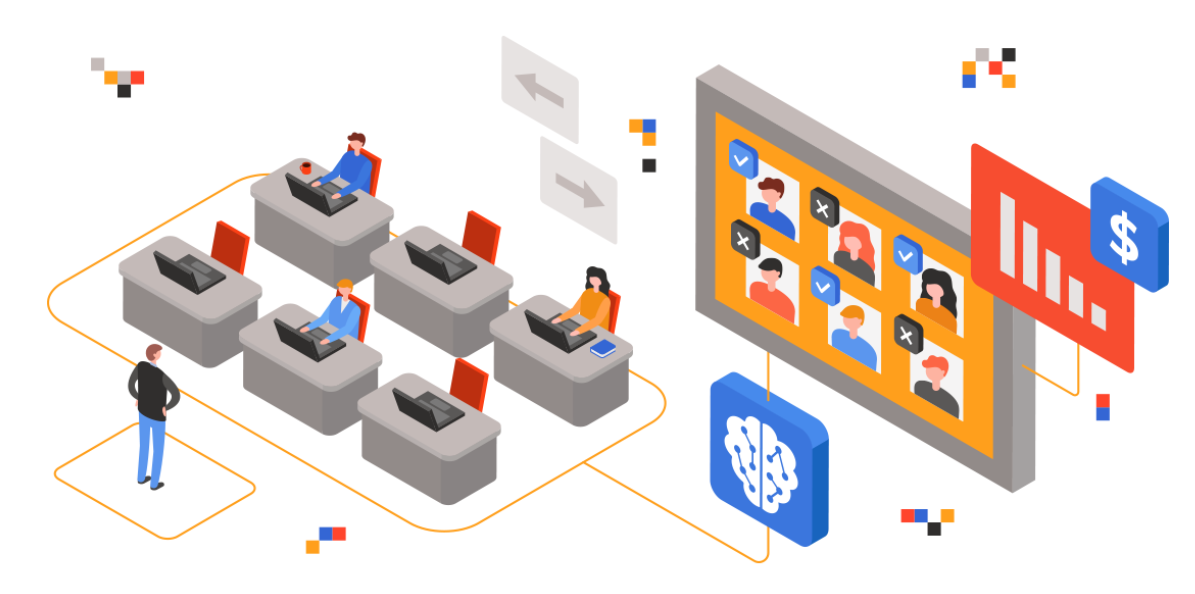

### Agenda:
1. [Frame the Problem / Business Case](#problem)
2. [Gathering the Data](#data)
3. [Data Pre-Pocessing](#processing)
4. [EDA](#eda)
5. [Feature Engineering](#engg)
6. [Model Training, Evaluation and Selection](#model)

<a id='problem'></a>

## 1. Frame the Problem / Business Case

### Background:
- Hiring and retaining employees are extremely complex tasks that require capital, time and skills
- Small business owners spend **40% of their working** hours on tasks that do **not** generate any income such as hiring
- Companies spend **15%-20%** of the employee's salary to recruit a new candidate
- An average company loses anywhere **between 1% and 2.5%** of their total revenue on the time it takes to bring a new hire up to speed
- It takes **52 days** on average to fill a position

### Problem Statement:
- You work as a data scientist at a Multi-National Corporation
- The HR team collected extensive data on their employees and approached you to develop a model that could predict which employees are more likely to quit
- The team provided you with an extensive dataset, a sample of which is provided: 
    - JobInvolvement
    - Education
    - JobSatisfaction
    - PerformanceRating
    - RelationshipSatisfaction
    - WorkLifeBalance

<a id='data'></a>

## 2. Gathering the Data

In [20]:
import pandas as pd

# Load the HR dataset
df = pd.read_csv("Human_Resources.csv")

# Displaying the first 5 rows to know the data
df.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


In [21]:
# Check the number of rows and columns
print("Dataset Shape:", df.shape)

# Check the column names
print("\nColumn Names:")
print(df.columns.tolist())

# Check data types and non-null values
print("\nDataset Information:")
df.info()

Dataset Shape: (1470, 35)

Column Names:
['Age', 'Attrition', 'BusinessTravel', 'DailyRate', 'Department', 'DistanceFromHome', 'Education', 'EducationField', 'EmployeeCount', 'EmployeeNumber', 'EnvironmentSatisfaction', 'Gender', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobRole', 'JobSatisfaction', 'MaritalStatus', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'Over18', 'OverTime', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StandardHours', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Age                       1470 non-null   int64 
 1   Attrition                 1470 non-null   ob

In [22]:
# Check for missing values
print("Missing values in each column:")
print(df.isnull().sum())

# Check for duplicate rows
print("\nNumber of duplicate rows:", df.duplicated().sum())

Missing values in each column:
Age                         0
Attrition                   0
BusinessTravel              0
DailyRate                   0
Department                  0
DistanceFromHome            0
Education                   0
EducationField              0
EmployeeCount               0
EmployeeNumber              0
EnvironmentSatisfaction     0
Gender                      0
HourlyRate                  0
JobInvolvement              0
JobLevel                    0
JobRole                     0
JobSatisfaction             0
MaritalStatus               0
MonthlyIncome               0
MonthlyRate                 0
NumCompaniesWorked          0
Over18                      0
OverTime                    0
PercentSalaryHike           0
PerformanceRating           0
RelationshipSatisfaction    0
StandardHours               0
StockOptionLevel            0
TotalWorkingYears           0
TrainingTimesLastYear       0
WorkLifeBalance             0
YearsAtCompany              0
YearsInCu

In [23]:
# Check unique value counts across all features
unique_counts = df.nunique().sort_values()
print("Unique value count per column:")
print(unique_counts)

Unique value count per column:
Over18                         1
StandardHours                  1
EmployeeCount                  1
Gender                         2
Attrition                      2
PerformanceRating              2
OverTime                       2
MaritalStatus                  3
Department                     3
BusinessTravel                 3
StockOptionLevel               4
EnvironmentSatisfaction        4
JobInvolvement                 4
JobSatisfaction                4
RelationshipSatisfaction       4
WorkLifeBalance                4
Education                      5
JobLevel                       5
EducationField                 6
TrainingTimesLastYear          7
JobRole                        9
NumCompaniesWorked            10
PercentSalaryHike             15
YearsSinceLastPromotion       16
YearsWithCurrManager          18
YearsInCurrentRole            19
DistanceFromHome              29
YearsAtCompany                37
TotalWorkingYears             40
Age         

In [24]:
# Check target variable count and percentage
attrition_counts = df["Attrition"].value_counts()
attrition_percent = df["Attrition"].value_counts(normalize=True) * 100

target_summary = pd.DataFrame(
    {"Count": attrition_counts, "Percentage (%)": attrition_percent.round(2)}
)

print("Target Variable (Attrition) Distribution:")
display(target_summary)

Target Variable (Attrition) Distribution:


,Count,Percentage (%)
Attrition,,
No,1233,83.88
Yes,237,16.12


<a id='processing'></a>

## 3. Data Pre-Pocessing 

In [25]:
# Drop columns that do not contribute to the model
cols_to_drop = ['EmployeeCount', 'StandardHours', 'Over18', 'EmployeeNumber']
df = df.drop(columns=cols_to_drop)

# Verify the drop
print("New Dataset Shape:", df.shape)
print("\nRemaining Columns:")
print(df.columns.tolist())

New Dataset Shape: (1470, 31)

Remaining Columns:
['Age', 'Attrition', 'BusinessTravel', 'DailyRate', 'Department', 'DistanceFromHome', 'Education', 'EducationField', 'EnvironmentSatisfaction', 'Gender', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobRole', 'JobSatisfaction', 'MaritalStatus', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'OverTime', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']


In [26]:
# Map binary categorical variables to 1 and 0
df['Attrition'] = df['Attrition'].map({'Yes': 1, 'No': 0})
df['OverTime'] = df['OverTime'].map({'Yes': 1, 'No': 0})
df['Gender'] = df['Gender'].map({'Male': 1, 'Female': 0})

# Verify the changes
print("Mapped Binary Columns:")
display(df[['Attrition', 'OverTime', 'Gender']].head())

Mapped Binary Columns:


,Attrition,OverTime,Gender
0,1,1,0
1,0,0,1
2,1,1,1
3,0,1,0
4,0,0,1


In [27]:
# One-Hot Encode remaining categorical columns (auto-detects 'object' types)
df = pd.get_dummies(df, drop_first=True, dtype=int)

# Verify the newly transformed dataset
print("Dataset Shape after One-Hot Encoding:", df.shape)
display(df.head())

Dataset Shape after One-Hot Encoding: (1470, 45)


,Age,Attrition,DailyRate,DistanceFromHome,Education,EnvironmentSatisfaction,Gender,HourlyRate,JobInvolvement,JobLevel,...,JobRole_Human Resources,JobRole_Laboratory Technician,JobRole_Manager,JobRole_Manufacturing Director,JobRole_Research Director,JobRole_Research Scientist,JobRole_Sales Executive,JobRole_Sales Representative,MaritalStatus_Married,MaritalStatus_Single
0,41,1,1102,1,2,2,0,94,3,2,...,0,0,0,0,0,0,1,0,0,1
1,49,0,279,8,1,3,1,61,2,2,...,0,0,0,0,0,1,0,0,1,0
2,37,1,1373,2,2,4,1,92,2,1,...,0,1,0,0,0,0,0,0,0,1
3,33,0,1392,3,4,4,0,56,3,1,...,0,0,0,0,0,1,0,0,1,0
4,27,0,591,2,1,1,1,40,3,1,...,0,1,0,0,0,0,0,0,1,0


## 4. Exploratory Data Analysis (EDA)

Attrition
0    1233
1     237
Name: count, dtype: int64


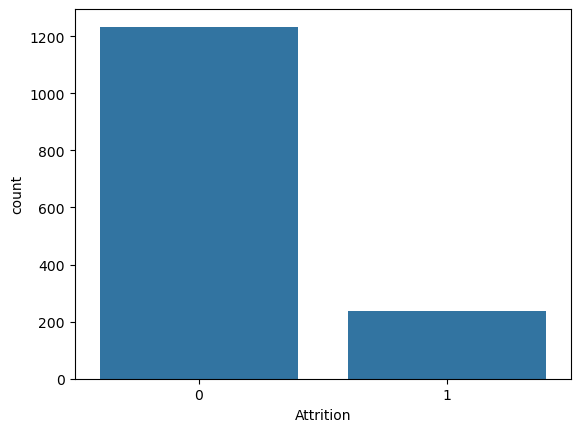

In [28]:
import matplotlib.pyplot as plt
import seaborn as sns
# Exact count of Attrition (1 = Yes, 0 = No)
print(df['Attrition'].value_counts())

# Visualize Attrition
sns.countplot(df, x="Attrition")
plt.show()

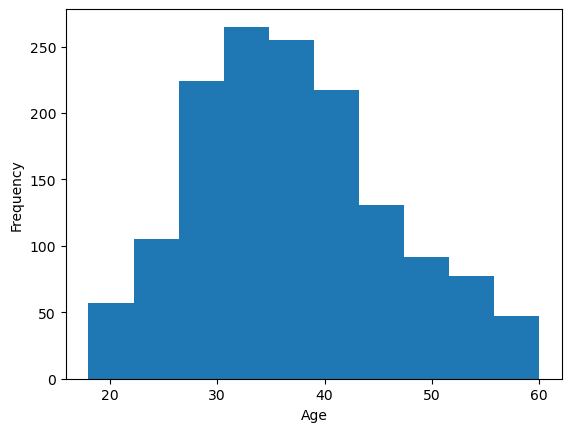

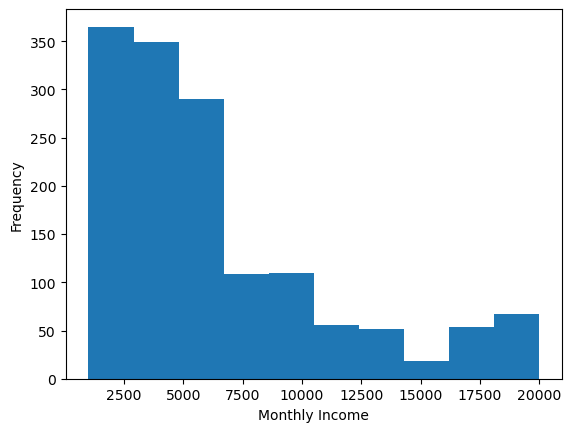

In [29]:
# Histogram for Age
plt.hist(df['Age'])
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.show()

# Histogram for Monthly Income
plt.hist(df['MonthlyIncome'])
plt.xlabel('Monthly Income')
plt.ylabel('Frequency')
plt.show()

In [30]:
# Statistical Summary
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
Age,1470.0,36.923810,9.135373,18.0,30.0,36.0,43.00,60.0
Attrition,1470.0,0.161224,0.367863,0.0,0.0,0.0,0.00,1.0
DailyRate,1470.0,802.485714,403.509100,102.0,465.0,802.0,1157.00,1499.0
DistanceFromHome,1470.0,9.192517,8.106864,1.0,2.0,7.0,14.00,29.0
Education,1470.0,2.912925,1.024165,1.0,2.0,3.0,4.00,5.0
EnvironmentSatisfaction,1470.0,2.721769,1.093082,1.0,2.0,3.0,4.00,4.0
Gender,1470.0,0.600000,0.490065,0.0,0.0,1.0,1.00,1.0
HourlyRate,1470.0,65.891156,20.329428,30.0,48.0,66.0,83.75,100.0
JobInvolvement,1470.0,2.729932,0.711561,1.0,2.0,3.0,3.00,4.0
JobLevel,1470.0,2.063946,1.106940,1.0,1.0,2.0,3.00,5.0


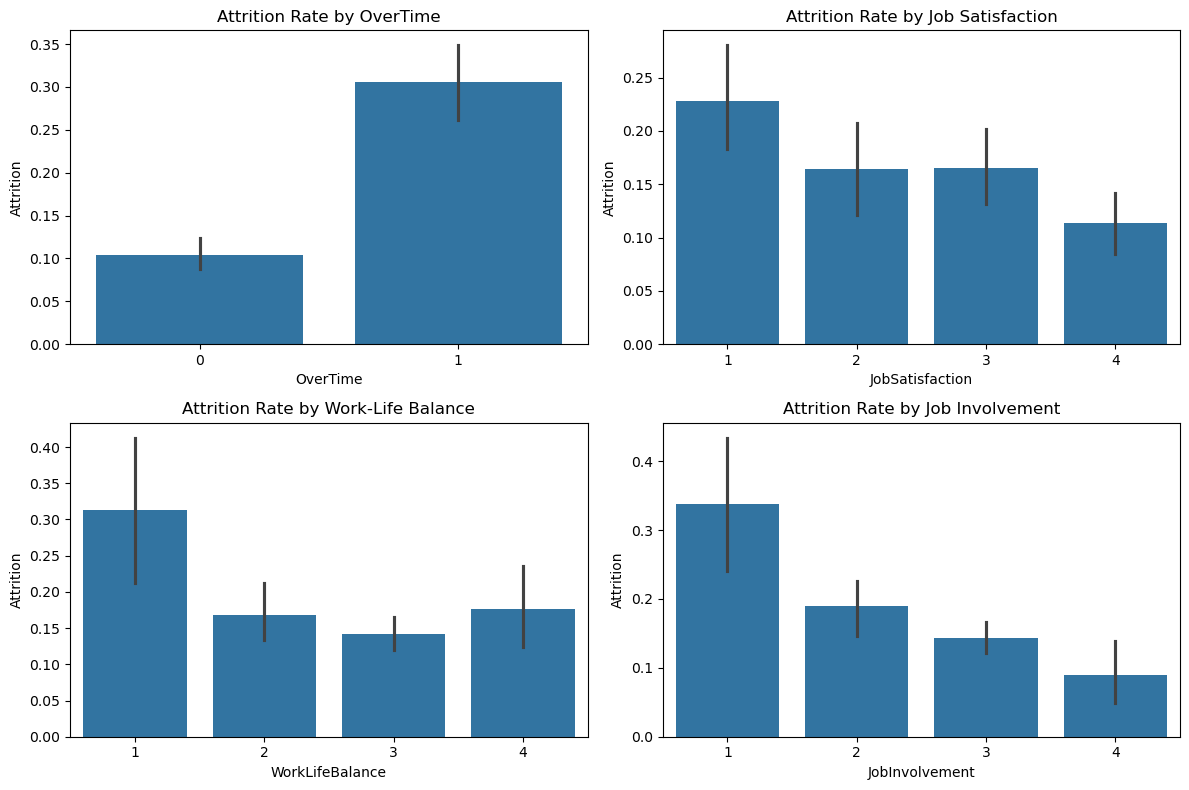

In [31]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set up the visualization grid
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

# Plotting Attrition rates across key business metrics
sns.barplot(x='OverTime', y='Attrition', data=df, ax=axes[0, 0])
axes[0, 0].set_title('Attrition Rate by OverTime')

sns.barplot(x='JobSatisfaction', y='Attrition', data=df, ax=axes[0, 1])
axes[0, 1].set_title('Attrition Rate by Job Satisfaction')

sns.barplot(x='WorkLifeBalance', y='Attrition', data=df, ax=axes[1, 0])
axes[1, 0].set_title('Attrition Rate by Work-Life Balance')

sns.barplot(x='JobInvolvement', y='Attrition', data=df, ax=axes[1, 1])
axes[1, 1].set_title('Attrition Rate by Job Involvement')

plt.tight_layout()
plt.show()

In [32]:
# Splitting Data into X and y
X = df.drop(columns='Attrition')
y = df['Attrition']

In [33]:
# Fixing Data Imbalance
from imblearn.over_sampling import SMOTE
from collections import Counter

smote = SMOTE(random_state=42)
X_res, y_res = smote.fit_resample(X, y)
print("Resampled training dataset shape:", Counter(y_res))

Resampled training dataset shape: Counter({1: 1233, 0: 1233})


In [34]:
# Feature Scaling
from sklearn.preprocessing import StandardScaler

sc = StandardScaler()
X_transformed = sc.fit_transform(X_res)

In [35]:
# Train Test Split
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X_transformed, y_res, test_size=0.3, random_state=42)

## 5. Feature Engineering


In [36]:
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from collections import Counter

# 1. Separate features (X) and target (y)
X = df.drop('Attrition', axis=1)
y = df['Attrition']

# 2. Fix Data Imbalance using SMOTE[cite: 9, 10, 12]
smote = SMOTE(random_state=42)
X_res, y_res = smote.fit_resample(X, y)
print("Resampled dataset shape:", Counter(y_res))

# 3. Feature Scaling[cite: 9, 10]
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_res)

# 4. Train-Test Split[cite: 9, 10]
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y_res, test_size=0.3, random_state=42)

Resampled dataset shape: Counter({1: 1233, 0: 1233})


<a id='model'></a>

## 6. Model Training, Evaluation and Selection

Logistic Regression Evaluation Metrics:
Accuracy: 0.9054
Precision: 0.9058
Recall: 0.9054
F1 Score: 0.9054

Decision Tree Evaluation Metrics:
Accuracy: 0.8311
Precision: 0.8314
Recall: 0.8311
F1 Score: 0.8310

Random Forest Evaluation Metrics:
Accuracy: 0.9203
Precision: 0.9214
Recall: 0.9203
F1 Score: 0.9202

AdaBoost Evaluation Metrics:
Accuracy: 0.8622
Precision: 0.8622
Recall: 0.8622
F1 Score: 0.8622

XGBoost Evaluation Metrics:
Accuracy: 0.9257
Precision: 0.9271
Recall: 0.9257
F1 Score: 0.9256

CatBoost Evaluation Metrics:
Accuracy: 0.9230
Precision: 0.9239
Recall: 0.9230
F1 Score: 0.9229

Stacking Classifier Evaluation Metrics:
Accuracy: 0.9257
Precision: 0.9268
Recall: 0.9257
F1 Score: 0.9256



,Model,Accuracy,Precision,Recall,F1-Score
0,XGBoost,0.925676,0.927062,0.925676,0.925621
1,Stacking Classifier,0.925676,0.926811,0.925676,0.925632
2,CatBoost,0.922973,0.923877,0.922973,0.922937
3,Random Forest,0.920270,0.921392,0.920270,0.920223
4,Logistic Regression,0.905405,0.905841,0.905405,0.905385
5,AdaBoost,0.862162,0.862171,0.862162,0.862160
6,Decision Tree,0.831081,0.831360,0.831081,0.831037


Best performing model: XGBoost


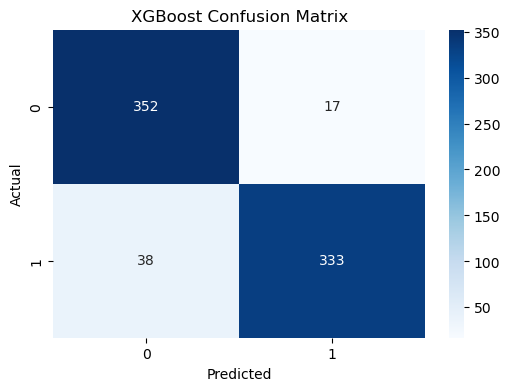

In [39]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, StackingClassifier
from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Define a function to evaluate each model using various metrics
def evaluate_model(y_test, y_pred, model_name):
    # Calculate the accuracy, precision, recall, and F1 score
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, average='weighted')
    recall = recall_score(y_test, y_pred, average='weighted')
    f1 = f1_score(y_test, y_pred, average='weighted')

    # Print the evaluation metrics
    print(f"{model_name} Evaluation Metrics:")
    print(f"Accuracy: {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall: {recall:.4f}")
    print(f"F1 Score: {f1:.4f}\n")

    return [model_name, accuracy, precision, recall, f1]

# Keep the fitted models around so the "best" one can be retrieved programmatically
fitted_models = {}

# Initialize the 6 base classification models
# (use_label_encoder removed: it's deprecated/removed in current xgboost and
#  'logloss' is the correct metric for this binary classification task)
models = {
    "Logistic Regression": LogisticRegression(random_state=42),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "AdaBoost": AdaBoostClassifier(random_state=42),
    "XGBoost": XGBClassifier(eval_metric='logloss', random_state=42),
    "CatBoost": CatBoostClassifier(verbose=0, random_state=42)
}

results = []

# Train and evaluate individual models
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    results.append(evaluate_model(y_test, y_pred, name))
    fitted_models[name] = model

# Initialize Stacking Classifier with Logistic Regression as the final estimator
estimators = [
    ('xgb', XGBClassifier(eval_metric='logloss', random_state=42)),
    ('cat', CatBoostClassifier(verbose=0, random_state=42))
]
stacking_model = StackingClassifier(
    estimators=estimators,
    final_estimator=LogisticRegression()
)

# Train and evaluate the stacking model
stacking_model.fit(X_train, y_train)
stacking_pred = stacking_model.predict(X_test)
results.append(evaluate_model(y_test, stacking_pred, "Stacking Classifier"))
fitted_models["Stacking Classifier"] = stacking_model

# Summary comparison dataframe of all trained models, ranked by Recall then Accuracy
model_comparison = pd.DataFrame(results, columns=['Model', 'Accuracy', 'Precision', 'Recall', 'F1-Score'])
model_comparison = model_comparison.sort_values(by=['Recall', 'Accuracy'], ascending=False).reset_index(drop=True)
display(model_comparison)

# Programmatically identify the best performer instead of assuming it's the stacking model
best_model_name = model_comparison.iloc[0]['Model']
best_pred = stacking_pred if best_model_name == "Stacking Classifier" else fitted_models[best_model_name].predict(X_test)
print(f"Best performing model: {best_model_name}")

# Generate the confusion matrix for the actual best performer and visualize it
cm = confusion_matrix(y_test, best_pred)
plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt='d', cmap="Blues")
plt.title(f'{best_model_name} Confusion Matrix')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.show()
